# **Sentiment Analysis**


● Analyze text data to classify it as positive, negative or neutra.

● Use NLP techniques and lexicons to detect specific emotions.

● Apply analysis on data from sources like Amazon reviews, social media, and news sites.

● Understand public opinion and trends through sentiment patterns.

● Use results to inform marketing, product development, or social insights



In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

from textblob import TextBlob
from wordcloud import WordCloud

!pip install nrclex
from nrclex import NRCLex

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.2 MB/s eta 0:00:00


In [15]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [2]:
df = pd.read_csv("amazon.csv")

In [14]:
df.head()

,product_name,category,rating,review_title,review_content,review
0,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,4.2,"Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,"Satisfied,Charging is really fast,Value for mo..."
1,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,4.0,"A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,"A Good Braided Cable for Your Type C Device,Go..."
2,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,3.9,"Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...","Good speed for earlier versions,Good Product,W..."
3,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,4.2,"Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...","Good product,Good one,Nice,Really nice product..."
4,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,4.2,"As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...","As good as original,Decent,Good one for second..."


In [4]:
print(df.columns)

Index(['product_id', 'product_name', 'category', 'discounted_price',
       'actual_price', 'discount_percentage', 'rating', 'rating_count',
       'about_product', 'user_id', 'user_name', 'review_id', 'review_title',
       'review_content', 'img_link', 'product_link'],
      dtype='object')


In [5]:
print(df.shape)

(1465, 16)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-null   object
dtypes: obj

In [7]:
df = df[
    [
        'product_name',
        'category',
        'rating',
        'review_title',
        'review_content'
    ]
]

In [8]:
df

,product_name,category,rating,review_title,review_content
0,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,4.2,"Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...
1,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,4.0,"A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...
2,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,3.9,"Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a..."
3,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,4.2,"Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou..."
4,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,4.2,"As good as original,Decent,Good one for second...","Bought this instead of original apple, does th..."
...,...,...,...,...,...
1460,Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...,Home&Kitchen|Kitchen&HomeAppliances|WaterPurif...,4,"Received the product without spanner,Excellent...","I received product without spanner,Excellent p..."
1461,Prestige Delight PRWO Electric Rice Cooker (1 ...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,4.1,"ok,everything was good couldn't return bcoz I ...","ok,got everything as mentioned but the measuri..."
1462,Bajaj Majesty RX10 2000 Watts Heat Convector R...,"Home&Kitchen|Heating,Cooling&AirQuality|RoomHe...",3.6,"very good,Work but front melt after 2 month,Go...","plastic but cool body ,u have to find sturdy s..."
1463,Havells Ventil Air DSP 230mm Exhaust Fan (Pist...,"Home&Kitchen|Heating,Cooling&AirQuality|Fans|E...",4,"Fan Speed is slow,Good quality,Good product,go...",I have installed this in my kitchen working fi...


In [9]:
df.isnull().sum()

,0
product_name,0
category,0
rating,0
review_title,0
review_content,0


In [10]:
df.dropna(inplace=True)

In [11]:
df['review'] = (
    df['review_title']
    + " "
    + df['review_content']
)

In [17]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

In [18]:
def clean_text(text):

    text = str(text)

    text = text.lower()

    text = re.sub(r'http\S+', '', text)

    text = re.sub(r'[^a-zA-Z\s]', '', text)

    words = text.split()

    words = [
        word
        for word in words
        if word not in stop_words
    ]

    text = " ".join(words)

    return text

In [19]:
df['clean_review'] = df['review'].apply(clean_text)

In [20]:
def rating_sentiment(rating):

    if rating >= 4:
        return 'Positive'

    elif rating == 3:
        return 'Neutral'

    else:
        return 'Negative'

In [25]:
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df['rating'] = df['rating'].fillna(df['rating'].mean())
df['rating_sentiment'] = (
    df['rating']
    .apply(rating_sentiment)
)

In [27]:
def text_sentiment(text):

    polarity = TextBlob(
        str(text)
    ).sentiment.polarity

    if polarity > 0:
        return 'Positive'

    elif polarity < 0:
        return 'Negative'

    else:
        return 'Neutral'

In [28]:
df['text_sentiment'] = (
    df['clean_review']
    .apply(text_sentiment)
)

In [29]:
df[
    [
        'clean_review',
        'text_sentiment'
    ]
].head()

,clean_review,text_sentiment
0,satisfiedcharging really fastvalue moneyproduc...,Positive
1,good braided cable type c devicegood quality p...,Positive
2,good speed earlier versionsgood productworking...,Positive
3,good productgood onenicereally nice productver...,Positive
4,good originaldecentgood one secondary usebest ...,Positive


In [30]:
df[
    [
        'clean_review',
        'text_sentiment'
    ]
].tail()

,clean_review,text_sentiment
1460,received product without spannerexcellent prod...,Positive
1461,okeverything good couldnt return bcoz needed e...,Positive
1462,goodwork front melt monthgood oneit durablerev...,Positive
1463,fan speed slowgood qualitygood productgoodold ...,Negative
1464,works perfectok good productnice product recom...,Positive


In [31]:
df['text_sentiment'].value_counts()

,count
text_sentiment,
Positive,1447
Negative,18


In [32]:
(
df['text_sentiment']
.value_counts(normalize=True)
*100
)

,proportion
text_sentiment,
Positive,98.771331
Negative,1.228669


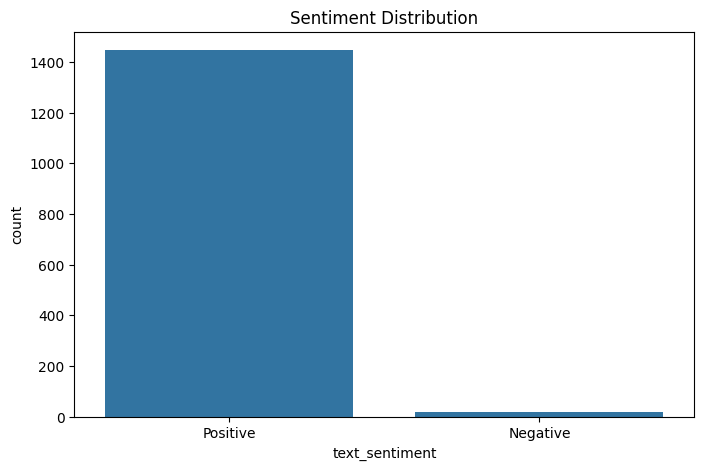

In [33]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='text_sentiment',
    data=df
)

plt.title(
    'Sentiment Distribution'
)

plt.show()

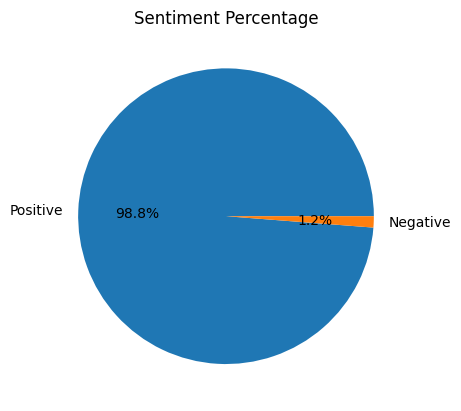

In [34]:
df[
'text_sentiment'
].value_counts().plot(
kind='pie',
autopct='%1.1f%%'
)

plt.title(
'Sentiment Percentage'
)

plt.ylabel('')

plt.show()

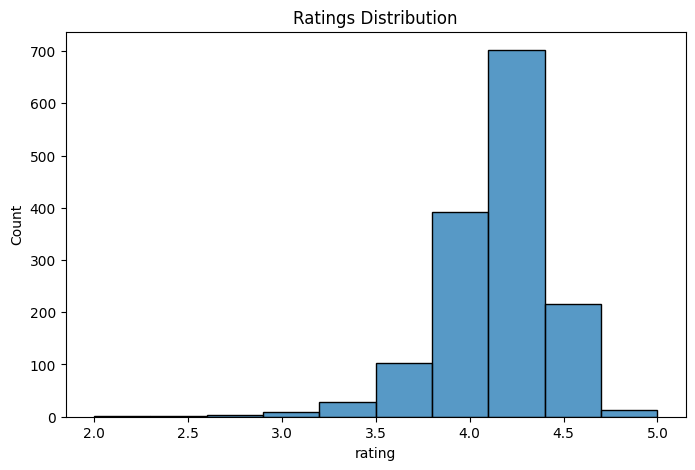

In [35]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['rating'],
    bins=10
)

plt.title(
'Ratings Distribution'
)

plt.show()

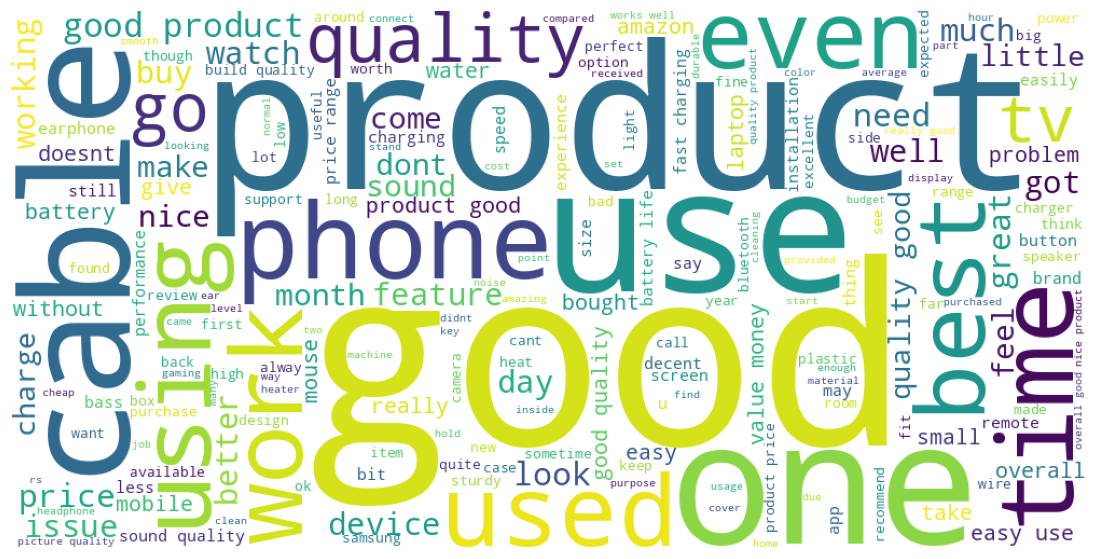

In [36]:
text = " ".join(
    df['clean_review']
)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(text)

plt.figure(figsize=(15,7))

plt.imshow(
    wordcloud
)

plt.axis('off')

plt.show()

In [48]:
pd.crosstab(
    df['category'],
    df['text_sentiment']
)

text_sentiment,Negative,Positive
category,,
Car&Motorbike|CarAccessories|InteriorAccessories|AirPurifiers&Ionizers,0,1
Computers&Accessories|Accessories&Peripherals|Adapters|USBtoUSBAdapters,0,2
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCHeadsets,0,1
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCMicrophones,0,2
Computers&Accessories|Accessories&Peripherals|Audio&VideoAccessories|PCSpeakers,0,2
...,...,...
"OfficeProducts|OfficePaperProducts|Paper|Stationery|Pens,Pencils&WritingSupplies|Pens&Refills|GelInkRollerballPens",0,2
"OfficeProducts|OfficePaperProducts|Paper|Stationery|Pens,Pencils&WritingSupplies|Pens&Refills|LiquidInkRollerballPens",0,2
"OfficeProducts|OfficePaperProducts|Paper|Stationery|Pens,Pencils&WritingSupplies|Pens&Refills|RetractableBallpointPens",0,2


In [49]:
top_products = (
    df.groupby(
        'product_name'
    )['rating']
    .mean()
    .sort_values(
        ascending=False
    )
)

top_products.head(10)

,rating
product_name,
"Syncwire LTG to USB Cable for Fast Charging Compatible with Phone 5/ 5C/ 5S/ 6/ 6S/ 7/8/ X/XR/XS Max/ 11/12/ 13 Series and Pad Air/Mini, Pod & Other Devices (1.1 Meter, White)",5.0
"REDTECH USB-C to Lightning Cable 3.3FT, [Apple MFi Certified] Lightning to Type C Fast Charging Cord Compatible with iPhone 14/13/13 pro/Max/12/11/X/XS/XR/8, Supports Power Delivery - White",5.0
"Amazon Basics Wireless Mouse | 2.4 GHz Connection, 1600 DPI | Type - C Adapter | Upto 12 Months of Battery Life | Ambidextrous Design | Suitable for PC/Mac/Laptop",5.0
"Swiffer Instant Electric Water Heater Faucet Tap Home-Kitchen Instantaneous Water Heater Tank less for Tap, LED Electric Head Water Heaters Tail Gallon Comfort(3000W) ((Pack of 1))",4.8
"Oratech Coffee Frother electric, milk frother electric, coffee beater, cappuccino maker, Coffee Foamer, Mocktail Mixer, Coffee Foam Maker, coffee whisker electric, Froth Maker, coffee stirrers electric, coffee frothers, Coffee Blender, (6 Month Warranty) (Multicolour)",4.8
"Instant Pot Air Fryer, Vortex 2QT, Touch Control Panel, 360° EvenCrisp™ Technology, Uses 95 % less Oil, 4-in-1 Appliance: Air Fry, Roast, Bake, Reheat (Vortex 1.97Litre, Black)",4.8
Spigen EZ Fit Tempered Glass Screen Protector for iPhone 14 Pro Max - 2 Pack (Sensor Protection),4.7
"Zuvexa USB Rechargeable Electric Foam Maker - Handheld Milk Wand Mixer Frother for Hot Milk, Hand Blender Coffee, Egg Beater (Black)",4.7
"FIGMENT Handheld Milk Frother Rechargeable, 3-Speed Electric Frother for Coffee with 2 Whisks and Coffee Decoration Tool, Coffee Frother Mixer, CRESCENT ENTERPRISES VRW0.50BK (A1)",4.7


In [50]:
negative_reviews = (
    df[
        df[
        'text_sentiment'
        ]
        ==
        'Negative'
    ]
)

negative_reviews[
[
'product_name',
'clean_review'
]
].head()

,product_name,clean_review
22,Samsung 80 cm (32 Inches) Wondertainment Serie...,goodsound low another brand comparing betterse...
145,Airtel DigitalTV DTH Remote SD/HD/HD Recording...,good productnot badworking airtel dthgoodok ba...
152,Samsung 80 cm (32 inches) Wondertainment Serie...,goodsound low another brand comparing betterse...
155,7SEVEN® Compatible for Tata Sky Remote Origina...,buy tv working difficult battery really bad pr...
179,7SEVEN® Bluetooth Voice Command Remote for Xia...,compatibilitygood one voice working propoergoo...


In [51]:
df.to_csv(
    'amazon_sentiment_analysis.csv',
    index=False
)